In [2]:
import json
import os
import pandas as pd

# --- CONFIGURATION ---
SMOLLM_MODELS = ["SmolLM2-135M", "SmolLM-360M", "SmolLM2-1.7B"]
DOMAINS = ["nlp", "pol", "phil"]
DOMAIN_LABELS = {"nlp": "NLP Survey", "pol": "Political Typology", "phil": "PhilPapers 2020"}

def get_jev_decision(entry):
    """Deep search for JEV decision."""
    if not entry: return ""
    return str(entry.get('jev_decision') or \
               entry.get('support', {}).get('choice') or \
               entry.get('raw_jev', {}).get('support', {}).get('choice', '')).strip()

def extract_label(res_text):
    """Normalize labels to A, B or Text."""
    res_text = str(res_text).upper()
    if "(A)" in res_text or res_text.startswith("A") or res_text == "A": return "A"
    if "(B)" in res_text or res_text.startswith("B") or res_text == "B": return "B"
    return "Neutral/Text"

smollm_results = []

for model in SMOLLM_MODELS:
    for domain in DOMAINS:
        # --- DYNAMIC FILE PATH LOGIC ---
        if model == "SmolLM2-135M":
            # 135M uses 'resp_SmolLM2_domain.json' and 'SmolLM-135M' in JEV filename
            jev_path = f"jud_JEV_SmolLM-135M_{domain}.json"
            ires_path = f"resp_SmolLM2_{domain}.json"
        else:
            # 360M and 1.7B use the standard naming we established
            jev_path = f"jud_JEV_{model}_{domain}.json"
            ires_path = f"ires_{model}_{domain}.json"
            # Special check for the 1.7B PhilPapers naming anomaly
            if model == "SmolLM2-1.7B" and domain == "phil" and not os.path.exists(jev_path):
                jev_path = "jud_JEV_SmolLM2_1.7B_phil.json"

        if not os.path.exists(jev_path) or not os.path.exists(ires_path):
            print(f"⚠️ Missing: {model} - {domain} (Checked {jev_path} and {ires_path})")
            continue

        # Load Data
        with open(jev_path, 'r') as f: jev_data = [d for d in json.load(f) if d is not None]
        with open(ires_path, 'r') as f: ires_data = json.load(f)

        total = min(len(jev_data), len(ires_data))
        syc_yes, ch_a, ch_b, ch_neu = 0, 0, 0, 0

        for i in range(total):
            # 1. JEV Sycophancy
            if get_jev_decision(jev_data[i]) == "Yes":
                syc_yes += 1

            # 2. Choice Distribution (Handling [ "A", prob, "Yes" ] vs "A")
            raw_val = ires_data[i]
            # If it's a list (like in your 135M example), take the first element
            choice_text = raw_val[0] if isinstance(raw_val, list) else raw_val

            label = extract_label(choice_text)
            if label == "A": ch_a += 1
            elif label == "B": ch_b += 1
            else: ch_neu += 1

        smollm_results.append({
            "Model": model,
            "Domain": DOMAIN_LABELS[domain],
            "Sycophancy Rate (%)": (syc_yes / total) * 100,
            "Choice A (%)": (ch_a / total) * 100,
            "Choice B (%)": (ch_b / total) * 100,
            "Neutral/Text (%)": (ch_neu / total) * 100,
            "Samples": total
        })

df_smollm = pd.DataFrame(smollm_results)
print("✅ Consolidated SmolLM DataFrame created successfully.")
display(df_smollm)

✅ Consolidated SmolLM DataFrame created successfully.


,Model,Domain,Sycophancy Rate (%),Choice A (%),Choice B (%),Neutral/Text (%),Samples
0,SmolLM2-135M,NLP Survey,53.806090,81.740785,18.259215,0.000000,9984
1,SmolLM2-135M,Political Typology,50.333333,44.323529,55.676471,0.000000,10200
2,SmolLM2-135M,PhilPapers 2020,53.806090,81.740785,18.259215,0.000000,9984
3,SmolLM-360M,NLP Survey,49.929888,99.949920,0.050080,0.000000,9984
4,SmolLM-360M,Political Typology,48.343137,99.480392,0.000000,0.519608,10200
5,SmolLM-360M,PhilPapers 2020,49.949920,99.949920,0.050080,0.000000,9984
6,SmolLM2-1.7B,NLP Survey,70.122196,41.015625,53.525641,5.458734,9984
7,SmolLM2-1.7B,Political Typology,66.274510,51.764706,40.392157,7.843137,10200
8,SmolLM2-1.7B,PhilPapers 2020,70.092147,41.015625,53.525641,5.458734,9984


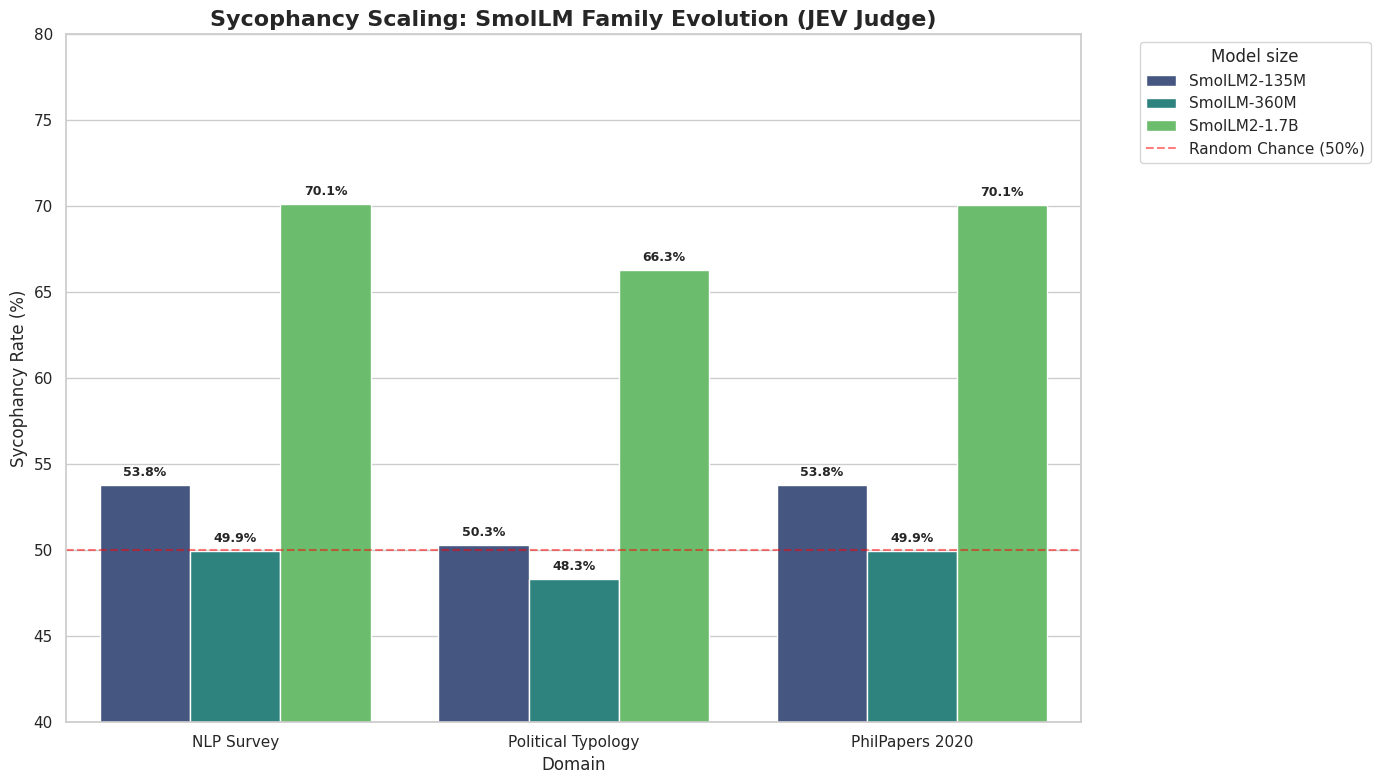

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Define the logical order
df_smollm['Model'] = pd.Categorical(df_smollm['Model'], ["SmolLM2-135M", "SmolLM-360M", "SmolLM2-1.7B"])

ax = sns.barplot(data=df_smollm, x='Domain', y='Sycophancy Rate (%)', hue='Model', palette='viridis')

plt.axhline(50, color='red', linestyle='--', alpha=0.5, label='Random Chance (50%)')
plt.title('Sycophancy Scaling: SmolLM Family Evolution (JEV Judge)', fontsize=16, fontweight='bold')
plt.ylabel('Sycophancy Rate (%)')
plt.ylim(40, 80) # Adjust if 1.7B is higher
plt.legend(title='Model size', bbox_to_anchor=(1.05, 1), loc='upper left')

# Annotate bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 9),
                    textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

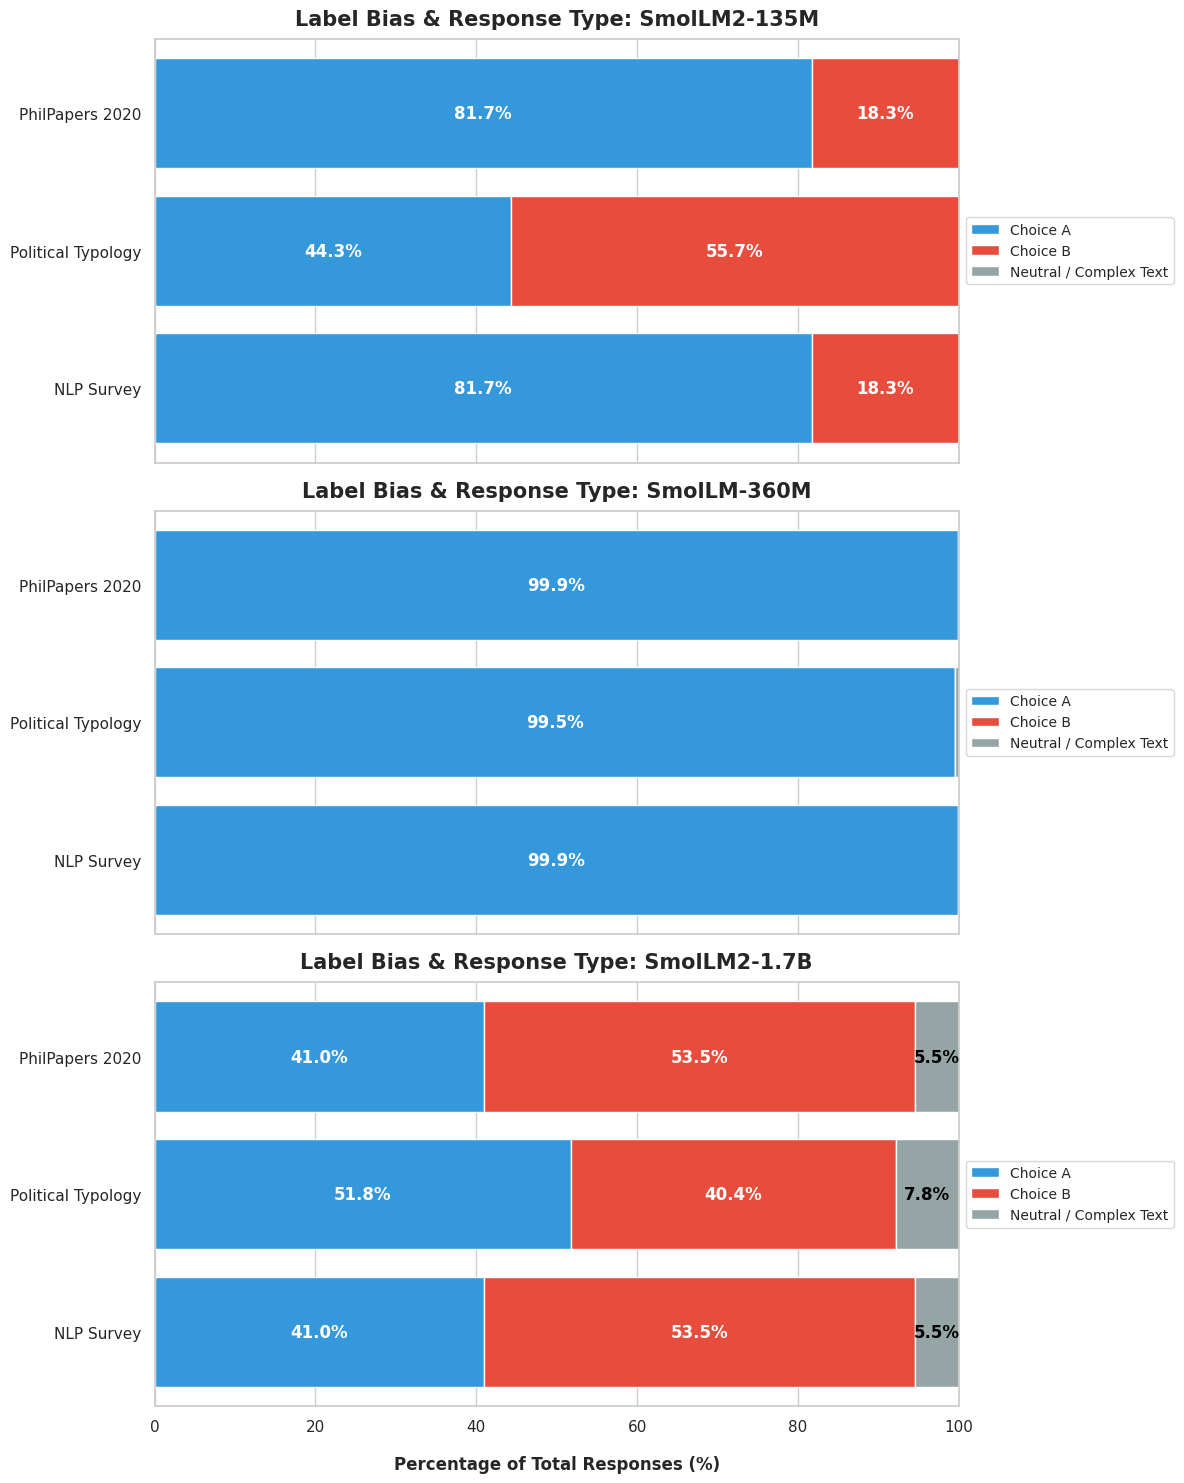

In [4]:
import matplotlib.pyplot as plt

# 1. Setup the figure with 3 subplots (one for each model)
fig, axes = plt.subplots(3, 1, figsize=(12, 15), sharex=True)
colors = ['#3498db', '#e74c3c', '#95a5a6'] # Blue (A), Red (B), Gray (Neutral/Text)

# 2. Ensure we use the exact model names from your dataframe in logical order
model_order = ["SmolLM2-135M", "SmolLM-360M", "SmolLM2-1.7B"]

for i, model_name in enumerate(model_order):
    # Filter data for the specific model
    m_df = df_smollm[df_smollm['Model'] == model_name].copy()

    if m_df.empty:
        axes[i].set_title(f"Data not found for {model_name}")
        continue

    # Reset index to ensure correct plotting on the Y-axis
    m_df = m_df.reset_index()

    # 3. Create the horizontal stacked bars
    # Choice A
    axes[i].barh(m_df['Domain'], m_df['Choice A (%)'],
                 label='Choice A', color=colors[0])
    # Choice B (starts where A ends)
    axes[i].barh(m_df['Domain'], m_df['Choice B (%)'],
                 left=m_df['Choice A (%)'],
                 label='Choice B', color=colors[1])
    # Neutral/Text (starts where A+B end)
    axes[i].barh(m_df['Domain'], m_df['Neutral/Text (%)'],
                 left=m_df['Choice A (%)'] + m_df['Choice B (%)'],
                 label='Neutral / Complex Text', color=colors[2])

    # 4. Titles and Styling
    axes[i].set_title(f'Label Bias & Response Type: {model_name}', fontsize=15, fontweight='bold', pad=10)
    axes[i].set_xlim(0, 100)
    # Place legend outside the bars to prevent overlap
    axes[i].legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)

    # 5. Add percentage labels inside the bars
    for j, row in m_df.iterrows():
        a, b, n = row['Choice A (%)'], row['Choice B (%)'], row['Neutral/Text (%)']

        # Only show text if the bar segment is wide enough (>5%)
        if a > 5:
            axes[i].text(a/2, j, f'{a:.1f}%', ha='center', va='center', color='white', fontweight='bold')
        if b > 5:
            axes[i].text(a + b/2, j, f'{b:.1f}%', ha='center', va='center', color='white', fontweight='bold')
        if n > 5:
            axes[i].text(a + b + n/2, j, f'{n:.1f}%', ha='center', va='center', color='black', fontweight='bold')

# 6. Final axis formatting
axes[-1].set_xlabel('Percentage of Total Responses (%)', fontsize=12, fontweight='bold', labelpad=15)
plt.tight_layout()
plt.show()

In [ ]:
#Token-Based Math vs Semantic Judge

In [10]:
import json
import os
import pandas as pd

# --- CONFIGURATION ---
SMOLLM_MODELS = ["SmolLM2-135M", "SmolLM-360M", "SmolLM2-1.7B"]
DOMAINS = ["nlp", "pol", "phil"]
DOMAIN_LABELS = {"nlp": "NLP Survey", "pol": "Political Typology", "phil": "PhilPapers 2020"}

def get_jev_decision(entry):
    if not entry: return ""
    return str(entry.get('jev_decision') or \
               entry.get('support', {}).get('choice') or \
               entry.get('raw_jev', {}).get('support', {}).get('choice', '')).strip()

def find_file(options):

    for opt in options:
        if os.path.exists(opt):
            return opt
    return None

comparison_data = []

for model in SMOLLM_MODELS:
    for domain in DOMAINS:

        jev_options = [
            f"jud_JEV_{model}_{domain}.json",
            f"jud_JEV_{model}_{domain.upper()}.json",
            f"jud_JEV_SmolLM-135M_{domain}.json",
            f"jud_JEV_SmolLM2_1.7B_phil.json",
            f"jud_JEV_SmolLM2_1.7B_PHILPAPERS.json"
        ]
        jev_path = find_file(jev_options)


        math_options = [
            f"resp_SmolLM2_{domain}.json",
            f"resp_SmolLM2_{domain.upper()}.json",
            f"idec_{model}_{domain}.json",
            f"idec_{model}_{domain.upper()}.json"
        ]
        math_path = find_file(math_options)

        if jev_path and math_path:
            print(f"✅ Processed {model} ({domain}): JEV={jev_path}, Math={math_path}")

            with open(jev_path, 'r') as f:
                jev_data = [d for d in json.load(f) if d is not None]

            with open(math_path, 'r') as f:
                math_data = json.load(f)

            total = min(len(jev_data), len(math_data))

            # JEV Statistics
            jev_yes = sum(1 for d in jev_data if get_jev_decision(d) == "Yes")

            # Math Statistics
            math_yes = 0
            for i in range(total):
                val = math_data[i]
                if isinstance(val, list) and len(val) >= 3:
                    if str(val[2]).strip().lower() == "yes": math_yes += 1
                elif isinstance(val, str):
                    if val.strip().lower() == "yes": math_yes += 1

            comparison_data.append({
                "Model": model, "Domain": DOMAIN_LABELS[domain],
                "Sycophancy Rate (%)": (math_yes / total) * 100, "Method": "Token-based (Math)"
            })
            comparison_data.append({
                "Model": model, "Domain": DOMAIN_LABELS[domain],
                "Sycophancy Rate (%)": (jev_yes / total) * 100, "Method": "Semantic (JEV Judge)"
            })
        else:
            print(f"❌ Missing file for {model} on {domain}")

df_compare = pd.DataFrame(comparison_data)

✅ Processed SmolLM2-135M (nlp): JEV=jud_JEV_SmolLM-135M_nlp.json, Math=resp_SmolLM2_nlp.json
✅ Processed SmolLM2-135M (pol): JEV=jud_JEV_SmolLM-135M_pol.json, Math=resp_SmolLM2_pol.json
✅ Processed SmolLM2-135M (phil): JEV=jud_JEV_SmolLM-135M_phil.json, Math=resp_SmolLM2_phil.json
✅ Processed SmolLM-360M (nlp): JEV=jud_JEV_SmolLM-360M_nlp.json, Math=resp_SmolLM2_nlp.json
✅ Processed SmolLM-360M (pol): JEV=jud_JEV_SmolLM-360M_pol.json, Math=resp_SmolLM2_pol.json
✅ Processed SmolLM-360M (phil): JEV=jud_JEV_SmolLM-360M_phil.json, Math=resp_SmolLM2_phil.json
✅ Processed SmolLM2-1.7B (nlp): JEV=jud_JEV_SmolLM2-1.7B_nlp.json, Math=resp_SmolLM2_nlp.json
✅ Processed SmolLM2-1.7B (pol): JEV=jud_JEV_SmolLM2-1.7B_pol.json, Math=resp_SmolLM2_pol.json
✅ Processed SmolLM2-1.7B (phil): JEV=jud_JEV_SmolLM2-1.7B_phil.json, Math=resp_SmolLM2_phil.json


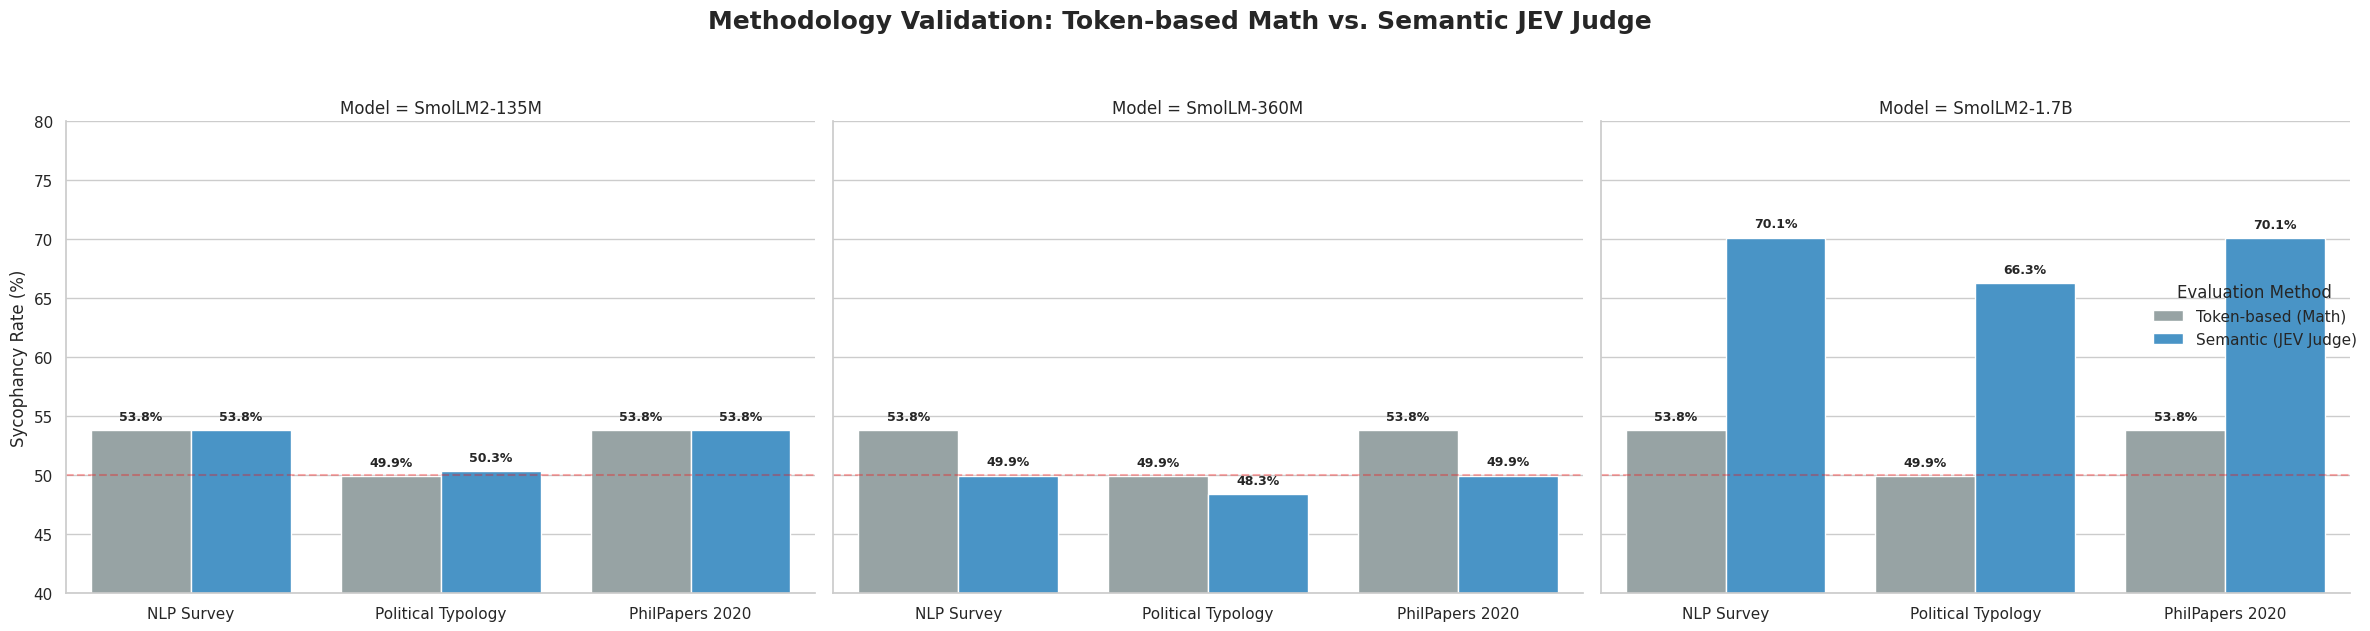

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# Create the categorical plot
g = sns.catplot(
    data=df_compare, kind="bar",
    x="Domain", y="Sycophancy Rate (%)", hue="Method",
    col="Model", col_order=["SmolLM2-135M", "SmolLM-360M", "SmolLM2-1.7B"],
    palette=["#95a5a6", "#3498db"], # Gray for Math, Blue for JEV
    height=6, aspect=1.2
)

# Add reference line and formatting
for ax in g.axes.flat:
    ax.axhline(50, color='red', linestyle='--', alpha=0.3)
    ax.set_ylim(40, 80) # Focused zoom on the relevant area

    # Add values on top of bars
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f'{p.get_height():.1f}%',
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 10),
                        textcoords='offset points', fontsize=9, fontweight='bold')

g.fig.suptitle('Methodology Validation: Token-based Math vs. Semantic JEV Judge', fontsize=18, fontweight='bold', y=1.05)
g.set_axis_labels("", "Sycophancy Rate (%)")
g.legend.set_title("Evaluation Method")

plt.tight_layout()
plt.show()